# ABCD matrix at a user-defined selection threshold

Events are **selected** as nutau-like if `prob_tau >= THRESHOLD`. The ABCD matrix counts:

| true ↓ / predicted →  | predicted nutau (score ≥ threshold) | predicted nue (score < threshold) |
|-----------------------|-------------------------------------|-----------------------------------|
| **true nutau**        | **A** = true positives              | **C** = false negatives           |
| **true nue**          | **B** = false positives             | **D** = true negatives            |

Derived: nutau efficiency (recovery) = A/(A+C), nue efficiency = B/(B+D), nue rejection = D/(B+D), purity = A/(A+B).

Input (set `SOURCE` below), either
* a training run directory with `eval_val.npz` (validation scores from `train.py`; true energy/direction available if saved), or
* an inference `scores.csv` (columns `true_label`, `prob_tau`, optionally `reco_energy_tev`), as used in `plot_infer.ipynb`.

Sections: 1 settings & load → 2 metrics and ABCD matrix → 3 plots as in `plot_infer.ipynb` (ROC, score distribution,
confusion matrix, calibration) → 4 ABCD across several thresholds → 5 threshold scan (recovery vs rejection) → 6 by energy.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score, log_loss, precision_score,
                             recall_score, roc_auc_score, roc_curve)
%matplotlib inline

## 1. Settings and input

In [2]:
# --- user settings -------------------------------------------------------------------------
SOURCE = "/mnt/scratch/baburish/doublepulse/gnn/Analysis/trained_model5TeV/full_nodist_aux1_bs64"
#   a run directory (uses eval_val.npz) or a path to an inference scores.csv
THRESHOLD = 0.6                              # selection: prob_tau >= THRESHOLD
SCAN_THRESHOLDS = [0.5, 0.6, 0.7, 0.8, 0.9]  # extra thresholds for the ABCD table in section 4
ALPHA = 0.9                                  # section 5: weight of nue rejection in the best-threshold score
# -------------------------------------------------------------------------------------------

energy, energy_label = None, None
if SOURCE.endswith(".csv"):
    df = pd.read_csv(SOURCE)
    y_true = df["true_label"].to_numpy().astype(int)
    y_prob = df["prob_tau"].to_numpy()
    if "reco_energy_tev" in df:
        energy, energy_label = np.log10(df["reco_energy_tev"].clip(lower=1e-3).to_numpy()), "log10 reco energy [TeV]"
else:
    d = np.load(os.path.join(SOURCE, "eval_val.npz"))
    y_true = d["trues"].astype(int)
    y_prob = d["preds"]
    if "y_aux" in d.files:   # standardised true log10 E is column 0
        energy = d["y_aux"][:, 0] * float(d["aux_log10e_std"]) + float(d["aux_log10e_mean"])
        energy_label = "true log10 primary energy [GeV]"

print(f"{SOURCE}\n{len(y_true)} events: {int((y_true == 1).sum())} nutau, {int((y_true == 0).sum())} nue")

/mnt/scratch/baburish/doublepulse/gnn/Analysis/trained_model5TeV/full_nodist_aux1_bs64
48585 events: 24292 nutau, 24293 nue


## 2. Metrics and ABCD matrix at `THRESHOLD`

threshold:          0.6
AUC:                0.6693
Accuracy:           0.5921
Precision (purity): 0.6917
Recall (tau eff.):  0.3322
F1:                 0.4488
Brier:              0.2273
Log loss:           0.6446
ABCD: A=8069  B=3597  C=16223  D=20696
  nutau efficiency A/(A+C): 0.3322
  nue efficiency   B/(B+D): 0.1481   (rejection 0.8519)
  purity           A/(A+B): 0.6917


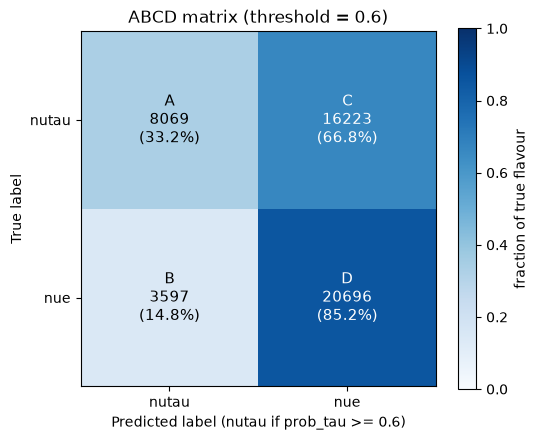

In [3]:
def abcd(y_true, y_prob, threshold):
    sel = y_prob >= threshold
    A = int(np.sum(sel & (y_true == 1)))    # true nutau, selected
    B = int(np.sum(sel & (y_true == 0)))    # true nue, selected
    C = int(np.sum(~sel & (y_true == 1)))   # true nutau, rejected
    D = int(np.sum(~sel & (y_true == 0)))   # true nue, rejected
    nan_div = lambda a, b: a / b if b else float("nan")
    return dict(threshold=threshold, A=A, B=B, C=C, D=D,
                tau_eff=nan_div(A, A + C), nue_eff=nan_div(B, B + D), nue_rejection=nan_div(D, B + D),
                purity=nan_div(A, A + B), selected=A + B)


m = abcd(y_true, y_prob, THRESHOLD)
y_pred = (y_prob >= THRESHOLD).astype(int)
print(f"threshold:          {THRESHOLD}")
print(f"AUC:                {roc_auc_score(y_true, y_prob):.4f}")
print(f"Accuracy:           {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision (purity): {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall (tau eff.):  {recall_score(y_true, y_pred):.4f}")
print(f"F1:                 {f1_score(y_true, y_pred):.4f}")
print(f"Brier:              {brier_score_loss(y_true, y_prob):.4f}")
print(f"Log loss:           {log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7)):.4f}")
print(f"ABCD: A={m['A']}  B={m['B']}  C={m['C']}  D={m['D']}")
print(f"  nutau efficiency A/(A+C): {m['tau_eff']:.4f}")
print(f"  nue efficiency   B/(B+D): {m['nue_eff']:.4f}   (rejection {m['nue_rejection']:.4f})")
print(f"  purity           A/(A+B): {m['purity']:.4f}")


def plot_abcd(ax, m, title=None):
    """2x2 ABCD matrix: rows = true label, columns = predicted label; counts and row fractions."""
    grid = np.array([[m["A"], m["C"]], [m["B"], m["D"]]])
    frac = grid / grid.sum(axis=1, keepdims=True)
    im = ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    names = [["A", "C"], ["B", "D"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{grid[i, j]}\n({100 * frac[i, j]:.1f}%)", ha="center", va="center",
                    fontsize=11, color="white" if frac[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1], ["nutau", "nue"])
    ax.set_yticks([0, 1], ["nutau", "nue"])
    ax.set_xlabel(f"Predicted label (nutau if prob_tau >= {m['threshold']:g})")
    ax.set_ylabel("True label")
    ax.set_title(title or f"ABCD matrix (threshold = {m['threshold']:g})")
    return im


fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = plot_abcd(ax, m)
plt.colorbar(im, ax=ax, label="fraction of true flavour")
plt.tight_layout()
plt.show()

## 3. Plots as in `plot_infer.ipynb`

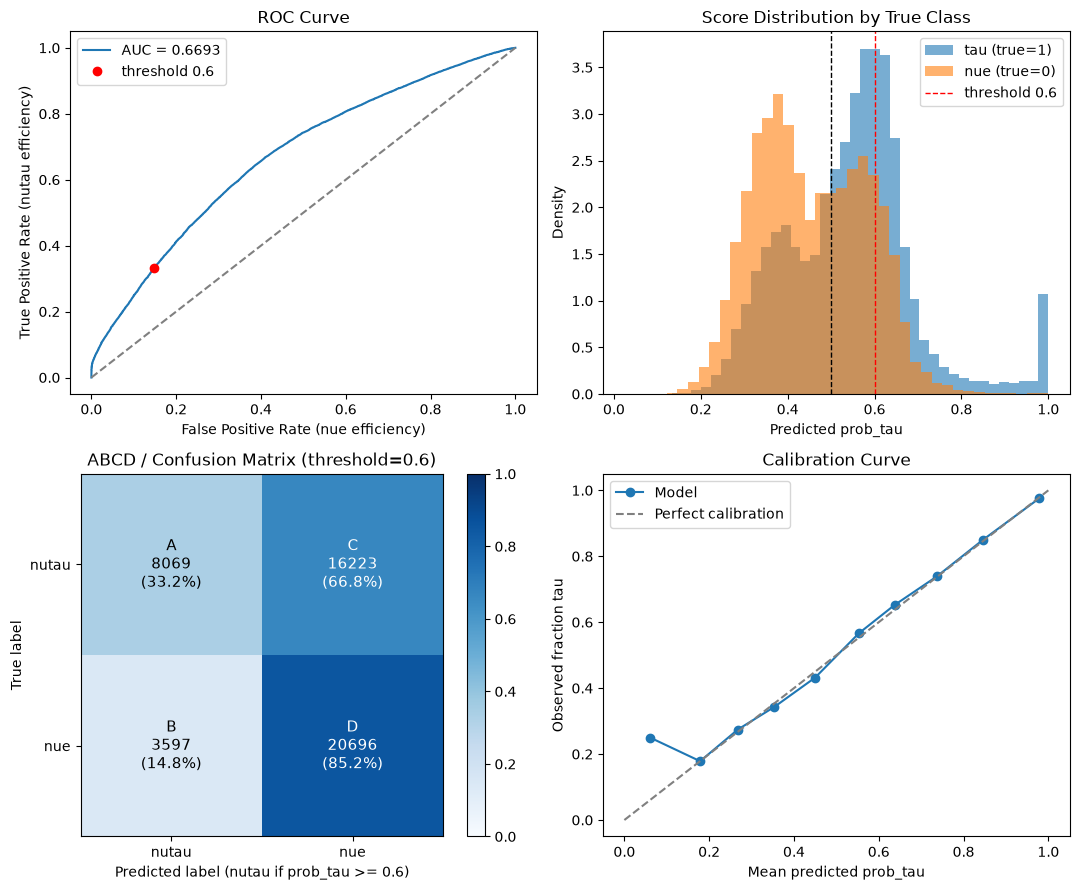

In [4]:
auc = roc_auc_score(y_true, y_prob)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# 1. ROC curve, with the working point of THRESHOLD
fpr, tpr, _ = roc_curve(y_true, y_prob)
axes[0, 0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0, 0].plot([0, 1], [0, 1], "--", color="gray")
axes[0, 0].plot(m["nue_eff"], m["tau_eff"], "o", color="red", label=f"threshold {THRESHOLD:g}")
axes[0, 0].set_xlabel("False Positive Rate (nue efficiency)")
axes[0, 0].set_ylabel("True Positive Rate (nutau efficiency)")
axes[0, 0].set_title("ROC Curve")
axes[0, 0].legend()

# 2. Score distribution by true class
axes[0, 1].hist(y_prob[y_true == 1], bins=40, alpha=0.6, label="tau (true=1)", density=True)
axes[0, 1].hist(y_prob[y_true == 0], bins=40, alpha=0.6, label="nue (true=0)", density=True)
axes[0, 1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0, 1].axvline(THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"threshold {THRESHOLD:g}")
axes[0, 1].set_xlabel("Predicted prob_tau")
axes[0, 1].set_ylabel("Density")
axes[0, 1].set_title("Score Distribution by True Class")
axes[0, 1].legend()

# 3. ABCD / confusion matrix
im = plot_abcd(axes[1, 0], m, f"ABCD / Confusion Matrix (threshold={THRESHOLD:g})")
plt.colorbar(im, ax=axes[1, 0])

# 4. Calibration curve (reliability diagram)
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10)
axes[1, 1].plot(prob_pred, prob_true, marker="o", label="Model")
axes[1, 1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
axes[1, 1].set_xlabel("Mean predicted prob_tau")
axes[1, 1].set_ylabel("Observed fraction tau")
axes[1, 1].set_title("Calibration Curve")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 4. ABCD at several thresholds

,A,B,C,D,tau_eff,nue_eff,nue_rejection,purity,selected
threshold,,,,,,,,,
0.5,15609,9365,8683,14928,0.6426,0.3855,0.6145,0.6250,24974
0.6,8069,3597,16223,20696,0.3322,0.1481,0.8519,0.6917,11666
0.7,2088,405,22204,23888,0.0860,0.0167,0.9833,0.8375,2493
0.8,1166,79,23126,24214,0.0480,0.0033,0.9967,0.9365,1245
0.9,840,21,23452,24272,0.0346,0.0009,0.9991,0.9756,861


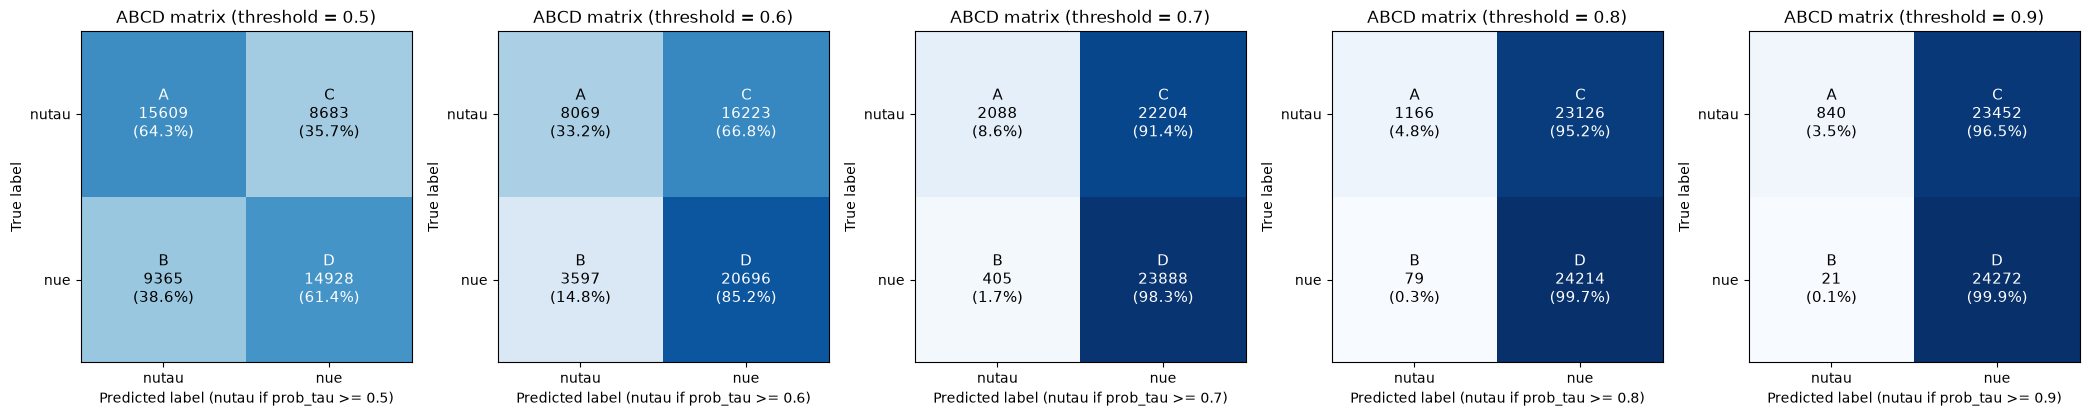

In [5]:
table = pd.DataFrame([abcd(y_true, y_prob, t) for t in SCAN_THRESHOLDS]).set_index("threshold")
display(table.round(4))

fig, axes = plt.subplots(1, len(SCAN_THRESHOLDS), figsize=(4.2 * len(SCAN_THRESHOLDS), 4))
for ax, t in zip(np.atleast_1d(axes), SCAN_THRESHOLDS):
    plot_abcd(ax, abcd(y_true, y_prob, t))
plt.tight_layout()
plt.show()

## 5. Threshold scan: nutau recovery vs nue rejection
Best threshold by `ALPHA * rejection + (1 - ALPHA) * recovery` (as in `plot_infer.ipynb`), and by recovery + rejection.

weighted (alpha=0.9)       best threshold 0.897 | tau recovery 0.0350 | nue rejection 0.9991 | purity 0.9759
recovery + rejection       best threshold 0.488 | tau recovery 0.6687 | nue rejection 0.5889 | purity 0.6193


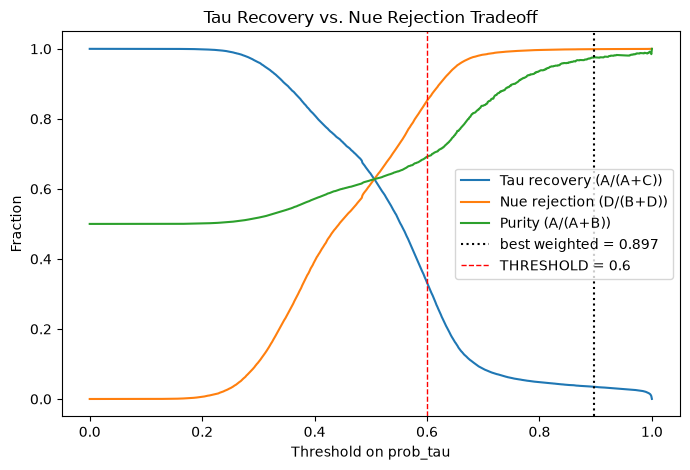

In [6]:
thresholds = np.linspace(0.0, 1.0, 1001)
scan = pd.DataFrame([abcd(y_true, y_prob, t) for t in thresholds])
recoveries, rejections = scan["tau_eff"].to_numpy(), scan["nue_rejection"].to_numpy()

weighted = ALPHA * rejections + (1 - ALPHA) * recoveries
best_w = int(np.nanargmax(weighted))
best_sum = int(np.nanargmax(recoveries + rejections))
for name, k in [(f"weighted (alpha={ALPHA})", best_w), ("recovery + rejection", best_sum)]:
    print(f"{name:26s} best threshold {thresholds[k]:.3f} | tau recovery {recoveries[k]:.4f} | "
          f"nue rejection {rejections[k]:.4f} | purity {scan['purity'][k]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(thresholds, recoveries, label="Tau recovery (A/(A+C))")
ax.plot(thresholds, rejections, label="Nue rejection (D/(B+D))")
ax.plot(thresholds, scan["purity"], label="Purity (A/(A+B))")
ax.axvline(thresholds[best_w], color="black", linestyle=":", linewidth=1.5,
           label=f"best weighted = {thresholds[best_w]:.3f}")
ax.axvline(THRESHOLD, color="red", linestyle="--", linewidth=1, label=f"THRESHOLD = {THRESHOLD:g}")
ax.set_xlabel("Threshold on prob_tau")
ax.set_ylabel("Fraction")
ax.set_title("Tau Recovery vs. Nue Rejection Tradeoff")
ax.legend()
plt.tight_layout()
plt.show()

## 6. ABCD and AUC in energy bins (if energy is available)

true log10 primary energy [GeV]


,n,A,B,C,D,tau_eff,nue_eff,purity,AUC
bin,,,,,,,,,
"[2.01, 3.93)",8098,984,934,1888,4292,0.3426,0.1787,0.5130,0.6506
"[3.93, 4.09)",8097,1219,610,2618,3650,0.3177,0.1432,0.6665,0.6695
"[4.09, 4.26)",8097,1149,534,2775,3639,0.2928,0.1280,0.6827,0.6750
"[4.26, 4.46)",8098,1199,518,2887,3494,0.2934,0.1291,0.6983,0.6784
"[4.46, 4.72)",8097,1467,540,2780,3310,0.3454,0.1403,0.7309,0.7046
"[4.72, 8.00)",8098,2051,461,3275,2311,0.3851,0.1663,0.8165,0.6830


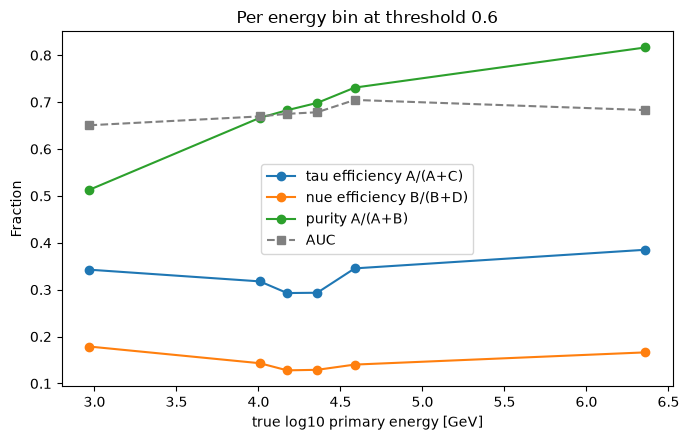

In [7]:
if energy is None:
    print("no energy information in this input")
else:
    edges = np.quantile(energy, np.linspace(0, 1, 7))
    edges[-1] += 1e-9
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mk = (energy >= lo) & (energy < hi)
        r = abcd(y_true[mk], y_prob[mk], THRESHOLD)
        r.update(bin=f"[{lo:.2f}, {hi:.2f})", n=int(mk.sum()),
                 AUC=roc_auc_score(y_true[mk], y_prob[mk]) if len(np.unique(y_true[mk])) == 2 else np.nan)
        rows.append(r)
    ebins = pd.DataFrame(rows).set_index("bin")
    print(energy_label)
    display(ebins[["n", "A", "B", "C", "D", "tau_eff", "nue_eff", "purity", "AUC"]].round(4))

    centers = 0.5 * (edges[1:] + edges[:-1])
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(centers, ebins["tau_eff"], "o-", label="tau efficiency A/(A+C)")
    ax.plot(centers, ebins["nue_eff"], "o-", label="nue efficiency B/(B+D)")
    ax.plot(centers, ebins["purity"], "o-", label="purity A/(A+B)")
    ax.plot(centers, ebins["AUC"], "s--", color="gray", label="AUC")
    ax.set_xlabel(energy_label)
    ax.set_ylabel("Fraction")
    ax.set_title(f"Per energy bin at threshold {THRESHOLD:g}")
    ax.legend()
    plt.tight_layout()
    plt.show()